# PPO analysis

Analysis of a trained PPO agent (`runs/NAME/model.zip`, written by `training/train_ppo.py`).
Use the `embodied_zfo` kernel. Plotting and simulation code lives in `viz/` and `training/`; this notebook imports it rather than redefining it.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

from training.metrics import EVAL_SEED, evaluate, ppo_policy
from training.train_ppo import make_ppo_env
from viz.animate_ppo import load_model, make_animation, save_animation

NAME = "ppo"   # run to analyze: runs/NAME/model.zip
model = load_model(NAME)

## Evaluation episodes

Per-episode metrics of the deterministic (mean) policy on the seeded evaluation episodes (`training.metrics.evaluate`): episode *i* is reset with seed `EVAL_SEED + i`, so any of them can be replayed below.

In [2]:
per_episode = evaluate(ppo_policy(model), make_ppo_env, n_episodes=20)

columns = ["seed", "glucose_target_error", "total_eaten", "eat_attempt_rate"]
print("  ".join(f"{c:>20}" for c in columns))
for i in range(len(per_episode["seed"])):
    print("  ".join(f"{per_episode[c][i]:>20.3f}" for c in columns))

/Users/juanmendez/miniconda3/envs/embodied_zfo/lib/python3.12/site-packages/gymnasium/spaces/box.py:231: UserWarning: WARN: Box low's precision lowered by casting to float32, current low.dtype=float64
  gym.logger.warn(
/Users/juanmendez/miniconda3/envs/embodied_zfo/lib/python3.12/site-packages/gymnasium/spaces/box.py:297: UserWarning: WARN: Box high's precision lowered by casting to float32, current high.dtype=float64
  gym.logger.warn(


                seed  glucose_target_error           total_eaten      eat_attempt_rate
           10000.000                 4.229                20.000                 0.491
           10001.000                 3.095                19.000                 0.507
           10002.000                 3.460                19.000                 0.468
           10003.000                 3.435                20.000                 0.522
           10004.000                 4.563                20.000                 0.512
           10005.000                 3.502                20.000                 0.470
           10006.000                 2.886                18.000                 0.439
           10007.000                 3.795                18.000                 0.476
           10008.000                 4.364                19.000                 0.388
           10009.000                 3.002                17.000                 0.437
           10010.000                 3.282 

## Choosing an episode

In [3]:
metrics = list(per_episode.keys())
relevant_metric = "glucose_target_error" # choose the metric you want to sort by, e.g. "eat_attempt_rate"
episode_index = np.argsort(per_episode[relevant_metric])[0]  # choose the episode with the lowest value of that metric
SEED = int(per_episode["seed"][episode_index])
print(SEED)

10013


## Animation

The agent in the arena (left), its glucose (right, top) and when it holds EAT, i.e. eat_cmd > EAT_THRESHOLD (right, bottom), as in `viz/animate_ppo.py`. Saved to `figures/ppo_NAME_seedSEED.mp4` (not embedded, so the notebook stays small in git); open the printed path to watch it.

In [4]:
fig, anim, episode = make_animation(model, NAME, SEED)
plt.close(fig)   # the video is the output; don't also draw its first frame here
path = save_animation(anim, NAME, SEED)
print(f"saved {path}")
print(", ".join(f"{k}={v:.3f}" for k, v in episode.items()))

saved /Users/juanmendez/Kozachkov/embodied_zfo/figures/ppo_ppo_seed10013.mp4
starved=0.000, glucose_mean=50.558, glucose_std=3.241, glucose_target_error=2.715, total_eaten=17.000, time=120.000, mean_move_cmd=0.324, mean_abs_turn_cmd=0.406, eat_attempt_rate=0.452, eat_efficiency=0.143, eat_out_of_reach=0.969, eat_during_cooldown=0.000, eat_opportunities=119.000, eat_held_time=54.200, eat_out_of_reach_time=52.500, eat_during_cooldown_time=0.000


## Policy probing

The actor's Gaussian on hand-built observations (`training/probe.py`): sweep one feature, hold the others fixed, and read the mean action (physical units, unclipped). No episodes are run, so this shows the learned rule itself. The deterministic policy (evaluation, the video) holds EAT where the mean `eat_cmd` is above `EAT_THRESHOLD`.

In [3]:
from training.probe import policy_gaussian, probe_observations
from viz.style import AGENT, EAT_MARK, FOOD, GRID, TEXT_MUTED, TURN
from zfo.env import EAT_THRESHOLD

env = make_ppo_env()
base = env.unwrapped
glucose = np.linspace(0, base.glucose_max, 101)
print(f"sensing_range={base.sensing_range:.1f}, eat_radius={base.eat_radius}: "
      f"in_reach needs proximity > {1 - base.eat_radius / base.sensing_range:.3f}")

sensing_range=141.4, eat_radius=2.0: in_reach needs proximity > 0.986


### EAT, steering and swimming vs glucose

Each condition is a fixed food geometry (keyword arguments of `probe_observations`: `proximity`, `bearing` in rad, `in_reach`, `can_eat`); glucose is swept for each. Turning: positive = left, so with food at bearing b a food-seeking turn has the sign of b.

In [4]:
# fixed observations that you feed into the policy, and sweep across glucose values to see how the policy responds
# bearing is angle to food relative to current heading of agent
CONDITIONS = { 
    "food ahead, far": dict(proximity=0.5),
    "food opposite direction, far": dict(proximity=0.5, bearing=np.pi),
    "food ahead, very far": dict(proximity=0.05),
    "food in reach": dict(proximity=0.99, in_reach=1.0),
}

std (physical units): move 0.37, turn 0.70, eat 0.48


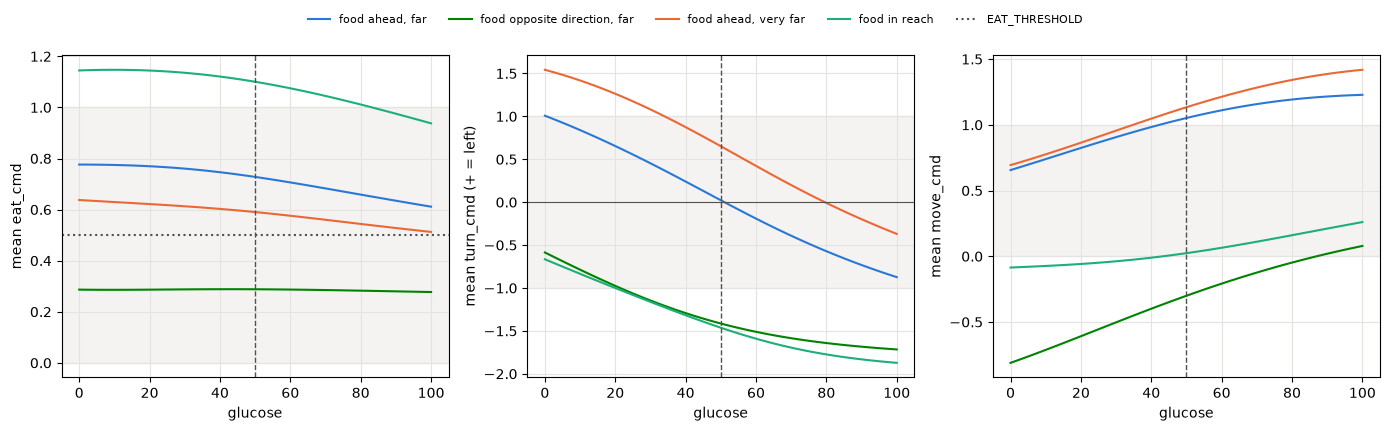

In [5]:
colors = [AGENT, EAT_MARK, TURN, FOOD, TEXT_MUTED]
fig, (ax_eat, ax_turn, ax_move) = plt.subplots(1, 3, figsize=(14, 4))
for color, (label, kwargs) in zip(colors, CONDITIONS.items()):
    mean, std = policy_gaussian(model, env, probe_observations(env, glucose, **kwargs))
    ax_eat.plot(glucose, mean[:, 2], color=color, label=label)
    ax_turn.plot(glucose, mean[:, 1], color=color)
    ax_move.plot(glucose, mean[:, 0], color=color)
ax_eat.axhline(EAT_THRESHOLD, color=TEXT_MUTED, linestyle=":", label="EAT_THRESHOLD")
for ax, ylabel in [(ax_eat, "mean eat_cmd"), (ax_turn, "mean turn_cmd (+ = left)"),
                   (ax_move, "mean move_cmd")]:
    ax.axvline(base.glucose_target, color=TEXT_MUTED, linestyle="--", linewidth=1)
    ax.set_xlabel("glucose")
    ax.set_ylabel(ylabel)
    ax.grid(color=GRID)
for ax in (ax_eat, ax_move):
    ax.axhspan(0, 1, color=GRID, alpha=0.4, zorder=0)   # the action's range; the mean can leave it
ax_turn.axhspan(-1, 1, color=GRID, alpha=0.4, zorder=0)
ax_turn.axhline(0, color=TEXT_MUTED, linewidth=0.8)
print(f"std (physical units): move {std[0]:.2f}, turn {std[1]:.2f}, eat {std[2]:.2f}")
fig.tight_layout()
fig.legend(*ax_eat.get_legend_handles_labels(), loc="lower center", bbox_to_anchor=(0.5, 1.0),
           ncol=len(CONDITIONS) + 1, fontsize=8, frameon=False);

### Steering vs bearing

Mean `turn_cmd` (positive = turn left) as the pellet's bearing goes around the agent (0 = ahead, +-pi = behind), at a few glucose levels. A food-seeking rule has the sign of the bearing.

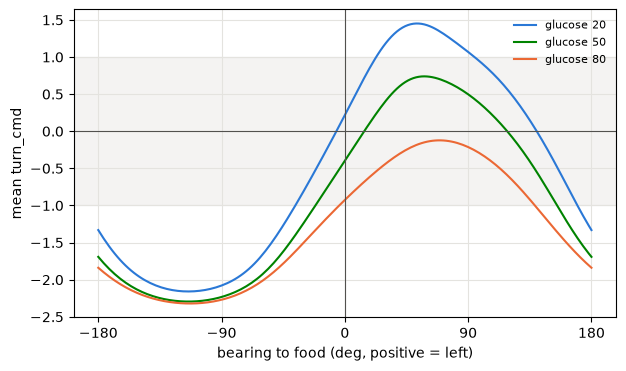

In [9]:
bearing = np.linspace(-np.pi, np.pi, 181)
fig, ax = plt.subplots(figsize=(7, 4))
for color, g in zip(colors, [20, base.glucose_target, 80]):
    mean, _ = policy_gaussian(model, env, probe_observations(env, g, proximity=0.8, bearing=bearing))
    ax.plot(np.degrees(bearing), mean[:, 1], color=color, label=f"glucose {g:.0f}")
ax.axhspan(-1, 1, color=GRID, alpha=0.4, zorder=0)
ax.axhline(0, color=TEXT_MUTED, linewidth=0.8)
ax.axvline(0, color=TEXT_MUTED, linewidth=0.8)
ax.set_xticks(range(-180, 181, 90))
ax.set_xlabel("bearing to food (deg, positive = left)")
ax.set_ylabel("mean turn_cmd")
ax.grid(color=GRID)
ax.legend(fontsize=8, frameon=False);